## 01-Enrich完善问题
- 要解决的问题：用户问题往往口语化，表达含糊或省略，与实际业务不匹配
- 理想情况：LLM 通过多次与用户主动沟通，收集信息，完善对用户意图的真实理解
- 基本思路：用户提问后，让 LLM 自己判断问题是否完整，重复`思考-转述-询问`流程，直至问题完整

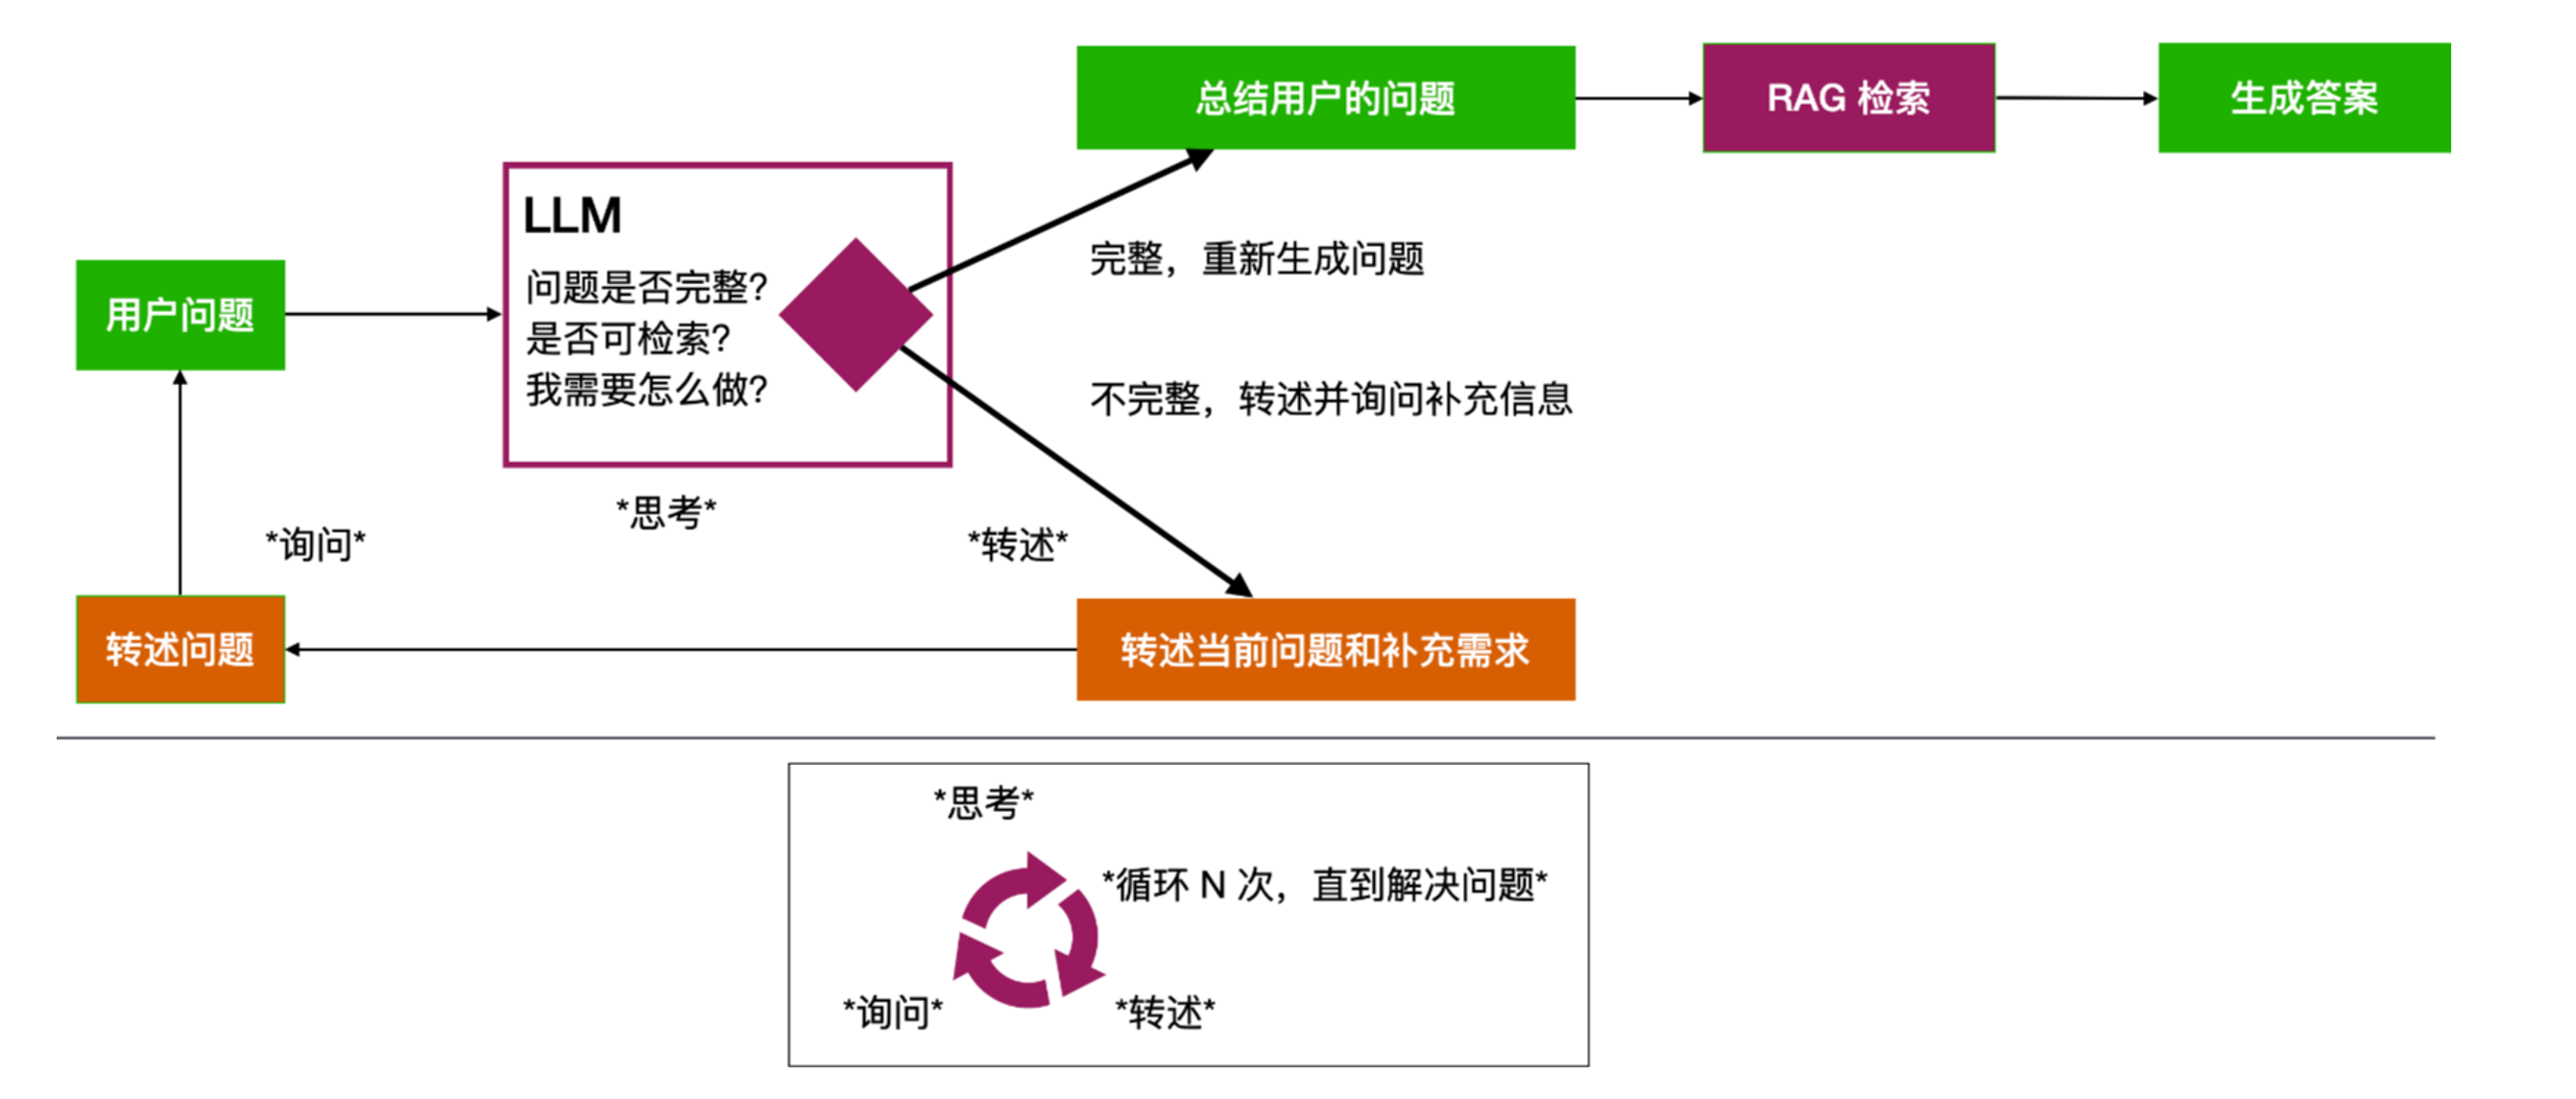

#### 初始化模型

In [1]:
import os
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(api_key=os.getenv("DASHSCOPE_API_KEY"), model="qwen3.7-max", base_url="https://ws-ots0tb33v08803wb.cn-beijing.maas.aliyuncs.com/compatible-mode/v1")

#### 业务能力定义池
`作用：系统能做什么，以及每个人物需要哪些信息才能完成`

In [2]:
# 1. 业务定义池（所有 AI 具备的能力）、是由人完成，更多的是由产品经理来定义。
CAPABILITIES = {
    "订机票": ["起点", "终点", "时间", "座位等级（经济舱/商务舱）", "座位偏好（靠窗/靠过道/无要求）"],
    "订酒店": ["城市", "入住日期", "离店日期", "房型（单间、大床房、双人房）", "人数"],
    "打车": ["出发地", "目的地", "车型"],
    "订餐厅": ["城市", "餐厅名", "人数", "时间"]
}

#### 动态规划器 (Planner)
`作用：根据用户输入，识别出用户想要办理哪些业务`

In [3]:
# --- 第一步：动态规划器 (Planner) ---
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import JsonOutputParser
planner_prompt = ChatPromptTemplate.from_template("""
你是一个行程规划专家。请分析用户的输入，从可选业务列表中识别出用户想要办理的所有业务。
可选业务：{available_tasks}

用户输入："{user_input}"

请仅返回一个 JSON 数组，包含识别到的业务名称。
示例：["订机票", "订酒店"]
""")

planner_chain = planner_prompt | llm | JsonOutputParser()

In [7]:
## 测试动态规划器
planner_chain.invoke({
    "available_tasks": str(list(CAPABILITIES.keys())),
    "user_input": "帮我订长沙去北京的机票"
})

['订机票']

#### 执行器 (Executor)

In [5]:
# --- 第二步：执行器 (Executor) ---
executor_prompt = ChatPromptTemplate.from_template("""
你现在是【{focus_task}】业务的专职处理插件。

### 上下文背景：
- 当前系统日期：{sys_date}
- 原始总需求："{global_context}"
- **已完成任务的数据(供参考联动)**：{global_memory}

### 任务：
1. 提取字段：{allowed_slots}。
2. **逻辑联动**：如果用户说“当天”、“同上”、“那里”，请从“已完成任务的数据”或“原始总需求”中寻找对应关联（如机票终点即酒店城市，机票时间即酒店入住时间）。
3. **确认机制**：如果信息已全，列出清单并问用户“是否准确？(1确认/0修改)”。
4. **结束判定**：如果用户回复“1”、“确认”、“准确”，必须将 is_done 设为 true。

### 格式:
1. 在用户补全的时候，以数字列表的方式列出待补全的数据项。

### 当前状态：
- 当前槽位数据：{current_slots}
- 用户最新输入：{user_input}
- 是否已询问过确认：{has_confirmed_asked}

返回规范 JSON：
{{
    "updated_slots": {{...}},
    "ai_response": "追问或确认话术",
    "is_done": true/false,
    "has_confirmed_asked": true/false
}}
""")

executor_chain = executor_prompt | llm | JsonOutputParser()

这个模块负责**单个任务的多轮对话执行**。

它每次调用时会收到这些信息：

| 参数 | 作用 |
|---|---|
| `focus_task` | 当前专注的任务，比如“订机票” |
| `sys_date` | 当前系统日期，帮助理解“明天”“后天”等时间 |
| `global_context` | 用户最开始的原始输入 |
| `global_memory` | 前面已经完成任务的结果 |
| `allowed_slots` | 当前任务允许收集的字段 |
| `current_slots` | 当前已经收集到的字段值 |
| `user_input` | 用户最新一句话 |
| `has_confirmed_asked` | 是否已经问过“是否确认” |



#### 主流程

In [6]:
from datetime import datetime
import json

def run_dynamic_agent(raw_input):
    print(f"\033[1;35m[原始输入]\033[0m: {raw_input}")

    # ============================================================
    # 第一步：动态规划
    # 调用规划器链，根据用户输入和系统可用能力列表，识别出需要执行的任务清单
    # ============================================================
    task_queue = planner_chain.invoke({
        "available_tasks": str(list(CAPABILITIES.keys())), # 告诉 LLM 有哪些业务可选
        "user_input": raw_input                            # 用户的原始需求
    })
    print(f"\033[1;34m[规划完成] 识别到任务清单：{task_queue}\033[0m")

    # ============================================================
    # 第二步：隔离执行任务
    # 遍历任务清单，逐个执行，每个任务拥有独立的槽位空间
    # ============================================================
    final_results = {} # 用于存储所有任务的最终结果
    sys_date = datetime.now().strftime("%Y-%m-%d") # 获取当前系统日期，供 LLM 理解"明天""后天"等相对时间
    for task in task_queue:
        # 如果识别到的任务不在能力表中，跳过（防止 LLM 幻觉产生不存在的任务）
        if task not in CAPABILITIES: continue
        print(f"\n\033[1;44m >>> 正在处理子任务：{task} <<< \033[0m")

        # 核心：初始化只包含本业务的，切断与其他业务的联系
        allowed_slots = CAPABILITIES[task]                    # 从能力表中获取该任务允许收集的字段
        current_slots = {k: None for k in allowed_slots}      # 初始化空槽位字典，所有字段初始值为 None
        has_confirmed_asked = False                           # 标记是否已经向用户发起过确认询问
        current_user_msg = ""                                 # 用户最新输入，第一轮为空，靠 global_context 驱动


        # 多轮对话循环：不断与用户交互，直到当前任务的所有槽位收集完毕并确认
        while True:
            # 调用执行器链，传入当前任务的全部上下文信息
            res = executor_chain.invoke({
                "focus_task": task,                                                 # 当前专注的任务名称
                "sys_date": sys_date,                                               # 系统当前日期
                "global_context": raw_input,                                        # 用户原始输入，提供全局背景
                "global_memory": json.dumps(final_results, ensure_ascii=False),     # 已完成任务的结果，供跨任务联动引用
                "allowed_slots": ", ".join(allowed_slots),                          # 允许收集的字段列表（逗号分隔字符串）
                "current_slots": json.dumps(current_slots, ensure_ascii=False),     # 当前已收集的槽位数据（JSON 字符串）
                "user_input": current_user_msg,                                     # 用户最新输入
                "has_confirmed_asked": has_confirmed_asked                          # 是否已询问过确认
            })

            # 更新本地状态：用 LLM 返回的最新槽位和确认标记覆盖旧值
            current_slots = res["updated_slots"]
            has_confirmed_asked = res["has_confirmed_asked"]

            # ============================================================
            # 退出条件判断：两种情况结束当前任务 AI 判定完成 或 代码硬拦截确认信号
            # 1. AI 自主判定所有槽位已收集完毕（is_done=True）
            # 2. AI 已发起确认询问，且用户手动输入 "1" 表示确认
            # ============================================================
            if res["is_done"] or (current_user_msg.strip() == "1" and has_confirmed_asked):
                print(f"\033[1;32m[✓] {task} 任务已最终确认。\033[0m")
                final_results[task] = current_slots
                break

            # 打印 AI 回复
            print(f"\n\033[1;33mAI ({task})：\033[0m\n{res['ai_response']}")

            # 获取用户输入
            current_user_msg = input("您的回答 (输入 quit 退出): ")
            if current_user_msg.lower() in ['exit', 'quit']: return

            # 如果用户在确认阶段输入 0，重置询问状态
            if current_user_msg.strip() == "0":
                has_confirmed_asked = False

    print("\n" + "=" * 30)
    print("\033[1;32m[全量任务交付报告]\033[0m")
    print(json.dumps(final_results, ensure_ascii=False, indent=2))

In [13]:
# 单任务：只订机票
user_input1 = "帮我订长沙去北京的机票"

# 双任务：订机票 + 订酒店
user_input2 = "帮我订长沙去北京的机票，还要北京的酒店"

# 多任务：订机票 + 订酒店 + 打车
user_input3 = "帮我订长沙去北京的机票，还要北京的酒店，到了北京帮我叫个专车去酒店"

run_dynamic_agent(user_input1)

[原始输入]: 帮我订长沙去北京的机票
[规划完成] 识别到任务清单：['订机票']

 >>> 正在处理子任务：订机票 <<< 

AI (订机票)：
好的，为您预订长沙到北京的机票。还需要您补充以下信息：
1. 出发时间
2. 座位等级（经济舱/商务舱）
3. 座位偏好（靠窗/靠过道/无要求）

AI (订机票)：
为您确认机票预订信息：
1. 起点：长沙
2. 终点：北京
3. 出发时间：2026-10-30
4. 座位等级：经济舱
5. 座位偏好：靠窗

请问以上信息是否准确？(1确认/0修改)
[✓] 订机票 任务已最终确认。

[全量任务交付报告]
{
  "订机票": {
    "起点": "长沙",
    "终点": "北京",
    "时间": "2026-10-30",
    "座位等级（经济舱/商务舱）": "经济舱",
    "座位偏好（靠窗/靠过道/无要求）": "靠窗"
  }
}


#### 拓展

#### 1. 用户输入
```
raw_input = "帮我订长沙去北京的机票"
```

#### 2. planner_chain
输入示例
```
{
    "available_tasks": "['订机票', '订酒店', '打车', '订餐厅']",
    "user_input": "帮我订长沙去北京的机票"
}
```

输入示例
```
["订机票"]
```

#### 3. executor_chain
第一轮输入示例
```
{
    "focus_task": "订机票",
    "sys_date": "2026-10-29",
    "global_context": "帮我订长沙去北京的机票",
    "global_memory": "{}",
    "allowed_slots": "起点, 终点, 时间, 座位等级（经济舱/商务舱）, 座位偏好（靠窗/靠过道/无要求）",
    "current_slots": "{
        "起点": None,
        "终点": None,
        "时间": None,
        "座位等级（经济舱/商务舱）": None,
        "座位偏好（靠窗/靠过道/无要求）": None
    }",
    "user_input": "",
    "has_confirmed_asked": False
}
```
第一轮输出示例
```
{
    "updated_slots": {
        "起点": "长沙",
        "终点": "北京",
        "时间": None,
        "座位等级（经济舱/商务舱）": None,
        "座位偏好（靠窗/靠过道/无要求）": None
    },
    "ai_response": "
        好的，已为您记录从长沙飞往北京的机票需求。为了帮您准确预订，请补充以下信息：
        1. 出发时间（具体日期）
        2. 座位等级（经济舱/商务舱）
        3. 座位偏好（靠窗/靠过道/无要求）
    ",
    "is_done": False,
    "has_confirmed_asked": False
}
```

更新
```
current_slots = res["updated_slots"]
has_confirmed_asked = res["has_confirmed_asked"]
```

判断
```
if res["is_done"] or (current_user_msg.strip() == "1" and has_confirmed_asked):
    print(f"\033[1;32m[✓] {task} 任务已最终确认。\033[0m")
    final_results[task] = current_slots
```

假设用户回复：
```
明天上午，经济舱，靠窗
```

第 2 轮输入示例

此时 `current_slots` 已经更新为第 1 轮返回的结果，所以第 2 轮输入变成：
```
{
    "focus_task": "订机票",
    "sys_date": "2026-10-29",
    "global_context": "帮我订长沙去北京的机票",
    "global_memory": "{}",
    "allowed_slots": "起点, 终点, 时间, 座位等级（经济舱/商务舱）, 座位偏好（靠窗/靠过道/无要求）",
    "current_slots": "{
        "起点": "长沙",
        "终点": "北京",
        "时间": None,
        "座位等级（经济舱/商务舱）": None,
        "座位偏好（靠窗/靠过道/无要求）": None
    }",
    "user_input": "明天上午，经济舱，靠窗",
    "has_confirmed_asked": False
}
```

第 2 轮输出示例
```
{
    "updated_slots": {
        "起点": "长沙",
        "终点": "北京",
        "时间": "明天上午",
        "座位等级（经济舱/商务舱）": "经济舱",
        "座位偏好（靠窗/靠过道/无要求）": "靠窗"
    },
    "ai_response": "请确认信息：长沙到北京，明天上午，经济舱，靠窗。输入1确认，0修改。",
    "is_done": False,
    "has_confirmed_asked": True
}
```

更新
```
current_slots = res["updated_slots"]
has_confirmed_asked = res["has_confirmed_asked"]
```

判断
```
if res["is_done"] or (current_user_msg.strip() == "1" and has_confirmed_asked):
    print(f"\033[1;32m[✓] {task} 任务已最终确认。\033[0m")
    final_results[task] = current_slots
```